# Problem statement: Create a ML model for predicting the price of a house based on variouse features.

In [1]:
import pandas as pd
import numpy as np

In [2]:
house = pd.read_csv(r"D:\SevenMentor\ML\workspace\Dhanaji_ml\dataset\house_prices.csv")

In [3]:
house

,city,locality,property_type,furnishing_status,facing,area_sqft,bedrooms,bathrooms,balconies,floor_number,total_floors,parking_spots,age_years,distance_to_city_center_km,distance_to_metro_km,distance_to_school_km,price_lakh
0,Chennai,Prime,Apartment,Semi-Furnished,East,1113,2,1,2,6,7,2,1,3.5,1.3,3.0,204.36
1,Hyderabad,Suburban,Apartment,Furnished,North-East,1109,3,3,1,0,2,0,6,5.6,2.5,0.4,135.32
2,Lucknow,Central,Independent House,Semi-Furnished,South-East,1169,3,2,2,0,4,0,13,11.9,1.2,2.8,68.45
3,Hyderabad,Suburban,Apartment,Unfurnished,South,593,1,1,1,5,11,2,2,9.1,2.2,0.8,73.23
4,Bengaluru,Suburban,Villa,Semi-Furnished,North,3082,6,5,3,6,11,1,4,3.1,1.6,2.1,586.09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,Pune,Central,Apartment,Unfurnished,West,1031,1,1,1,12,19,2,4,1.8,0.2,0.5,158.81
1196,Pune,Outskirts,Builder Floor,Unfurnished,North-East,1528,3,3,2,5,12,2,18,4.2,3.1,1.6,115.20
1197,Jaipur,Central,Apartment,Semi-Furnished,South-East,1135,3,3,3,1,14,2,5,4.8,6.6,3.2,85.29
1198,Delhi,Prime,Apartment,Furnished,North,1243,3,2,1,3,15,0,11,0.3,1.7,6.1,409.90


In [4]:
house.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   city                        1200 non-null   str    
 1   locality                    1200 non-null   str    
 2   property_type               1200 non-null   str    
 3   furnishing_status           1200 non-null   str    
 4   facing                      1200 non-null   str    
 5   area_sqft                   1200 non-null   int64  
 6   bedrooms                    1200 non-null   int64  
 7   bathrooms                   1200 non-null   int64  
 8   balconies                   1200 non-null   int64  
 9   floor_number                1200 non-null   int64  
 10  total_floors                1200 non-null   int64  
 11  parking_spots               1200 non-null   int64  
 12  age_years                   1200 non-null   int64  
 13  distance_to_city_center_km  1200 non-null   

In [5]:
house.describe().T

,count,mean,std,min,25%,50%,75%,max
area_sqft,1200.0,1417.113333,680.797214,300.00,982.000,1276.500,1702.000,4265.00
bedrooms,1200.0,2.610833,1.380569,1.00,1.000,2.000,3.000,6.00
bathrooms,1200.0,2.215833,1.261841,1.00,1.000,2.000,3.000,5.00
balconies,1200.0,1.869167,1.222004,0.00,1.000,2.000,3.000,4.00
floor_number,1200.0,4.948333,4.537380,0.00,1.000,4.000,7.000,20.00
total_floors,1200.0,10.349167,5.787212,1.00,5.000,10.000,15.000,20.00
parking_spots,1200.0,0.968333,0.810068,0.00,0.000,1.000,2.000,2.00
age_years,1200.0,8.209167,7.782087,0.00,3.000,6.000,12.000,45.00
distance_to_city_center_km,1200.0,5.964833,4.420518,0.20,2.900,4.900,7.800,44.50
distance_to_metro_km,1200.0,2.866083,2.300105,0.00,1.200,2.300,3.825,16.10


In [6]:
house.shape

(1200, 17)

In [7]:
house.isna().sum()

city                          0
locality                      0
property_type                 0
furnishing_status             0
facing                        0
area_sqft                     0
bedrooms                      0
bathrooms                     0
balconies                     0
floor_number                  0
total_floors                  0
parking_spots                 0
age_years                     0
distance_to_city_center_km    0
distance_to_metro_km          0
distance_to_school_km         0
price_lakh                    0
dtype: int64

In [8]:
house.duplicated().sum()

np.int64(0)

In [9]:
house.nunique()

city                            10
locality                         4
property_type                    5
furnishing_status                3
facing                           8
area_sqft                      895
bedrooms                         6
bathrooms                        5
balconies                        5
floor_number                    21
total_floors                    20
parking_spots                    3
age_years                       43
distance_to_city_center_km     189
distance_to_metro_km           106
distance_to_school_km           74
price_lakh                    1182
dtype: int64

# Preform EDA and Feature Enggnering

In [10]:
# chack data scatter

import matplotlib.pyplot as plt
import seaborn as sb

In [11]:


num = house.select_dtypes('number').columns.drop("price_lakh")
cat = house.select_dtypes('str').columns


In [12]:
house[num]

,area_sqft,bedrooms,bathrooms,balconies,floor_number,total_floors,parking_spots,age_years,distance_to_city_center_km,distance_to_metro_km,distance_to_school_km
0,1113,2,1,2,6,7,2,1,3.5,1.3,3.0
1,1109,3,3,1,0,2,0,6,5.6,2.5,0.4
2,1169,3,2,2,0,4,0,13,11.9,1.2,2.8
3,593,1,1,1,5,11,2,2,9.1,2.2,0.8
4,3082,6,5,3,6,11,1,4,3.1,1.6,2.1
...,...,...,...,...,...,...,...,...,...,...,...
1195,1031,1,1,1,12,19,2,4,1.8,0.2,0.5
1196,1528,3,3,2,5,12,2,18,4.2,3.1,1.6
1197,1135,3,3,3,1,14,2,5,4.8,6.6,3.2
1198,1243,3,2,1,3,15,0,11,0.3,1.7,6.1


In [13]:
house[cat]

,city,locality,property_type,furnishing_status,facing
0,Chennai,Prime,Apartment,Semi-Furnished,East
1,Hyderabad,Suburban,Apartment,Furnished,North-East
2,Lucknow,Central,Independent House,Semi-Furnished,South-East
3,Hyderabad,Suburban,Apartment,Unfurnished,South
4,Bengaluru,Suburban,Villa,Semi-Furnished,North
...,...,...,...,...,...
1195,Pune,Central,Apartment,Unfurnished,West
1196,Pune,Outskirts,Builder Floor,Unfurnished,North-East
1197,Jaipur,Central,Apartment,Semi-Furnished,South-East
1198,Delhi,Prime,Apartment,Furnished,North


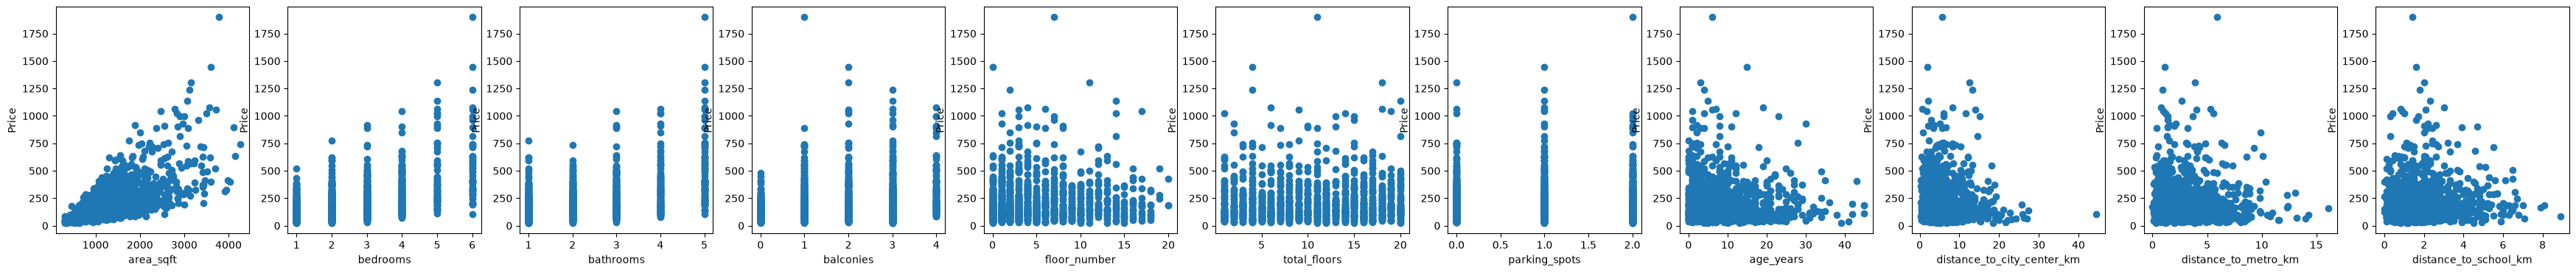

In [14]:
# plt.Figure(figsize=(10,4))

fig, axis = plt.subplots(1, len(num), figsize =(4*len(num), 4))

for ax, col in zip(axis, num):
    ax.scatter(house[col], house["price_lakh"])
    ax.set_xlabel(col)
    ax.set_ylabel("Price")

plt.show()

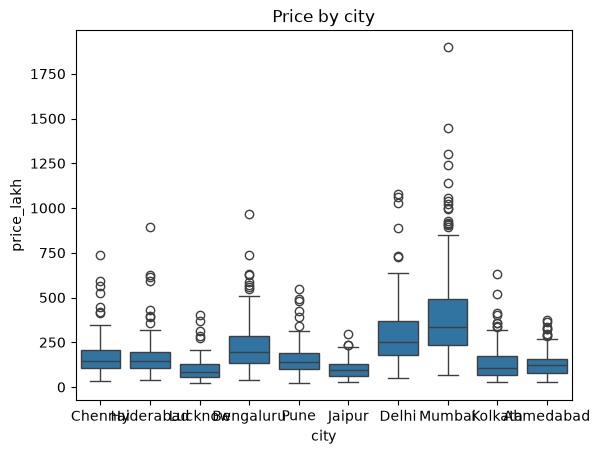

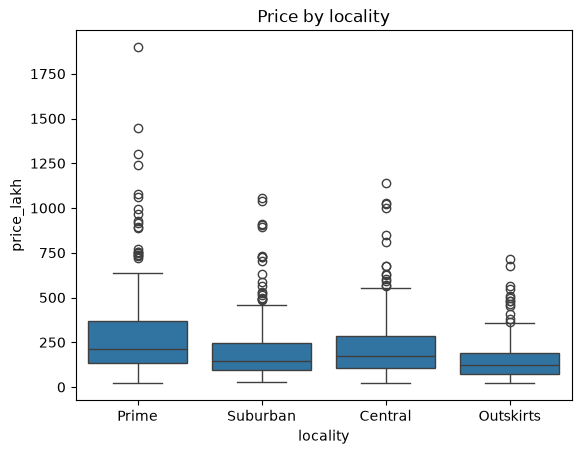

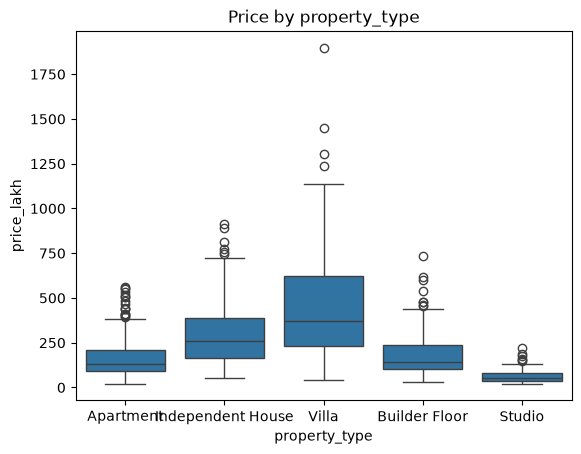

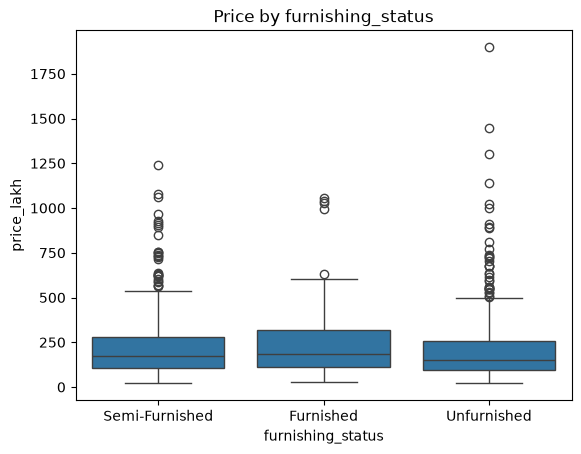

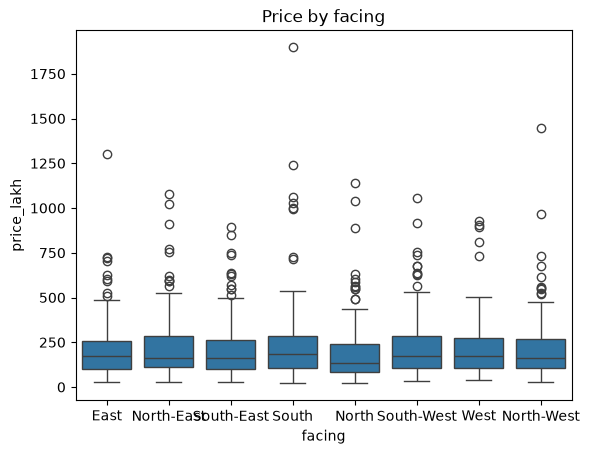

In [15]:
for col in cat:
    sb.boxplot(data=house, x=col, y='price_lakh')
    plt.title(f'Price by {col}')
    plt.show()

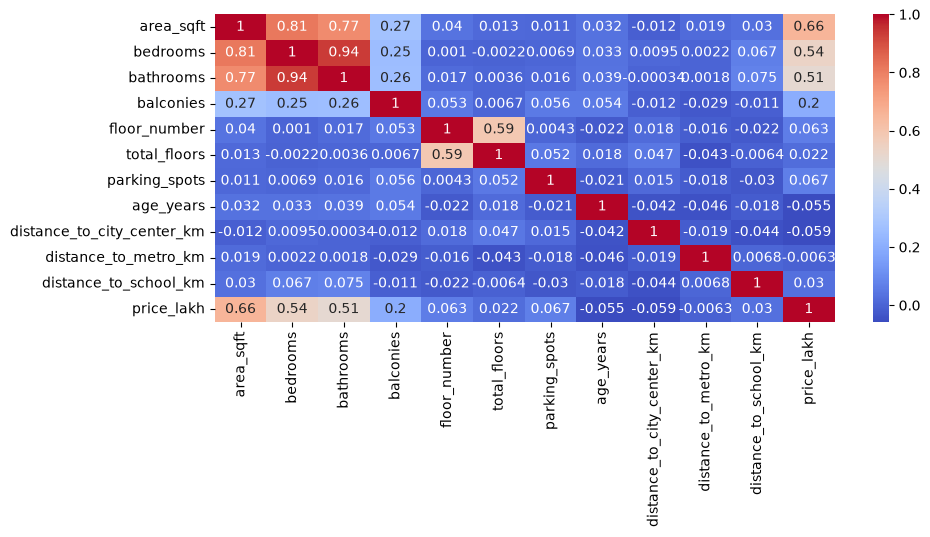

' note :\nthere bedrooms and bathrooms are high colreated with area_sqft.\nbedrooms and bathrooms are highly correted with each other\n\n'

In [16]:
# correlation analysis
# sb.Figure(figsize=(50,6))
plt.figure(figsize=(10, 4))
sb.heatmap(
    house.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.show()

''' note :
there bedrooms and bathrooms are high colreated with area_sqft.
bedrooms and bathrooms are highly correted with each other

'''

In [17]:
corr = house.corr(numeric_only=True)['price_lakh'].sort_values()
print(corr)

less_corr = ["distance_to_metro_km", "age_years", "distance_to_city_center_km"]

distance_to_city_center_km   -0.058714
age_years                    -0.055488
distance_to_metro_km         -0.006331
total_floors                  0.021901
distance_to_school_km         0.029942
floor_number                  0.063221
parking_spots                 0.066892
balconies                     0.201201
bathrooms                     0.505666
bedrooms                      0.535943
area_sqft                     0.655500
price_lakh                    1.000000
Name: price_lakh, dtype: float64


In [18]:

# chack dataset r2 scaore for finall chack data set is good or not and linear or non linear

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

y = house['price_lakh']
X = house[num]


In [19]:

baseline = cross_val_score(
    DummyRegressor(strategy="mean"),
    X, y, cv=5, scoring="r2"
).mean()

print("Baseline R2:", baseline)


model_r2= cross_val_score(  # for chacking linear relation
    LinearRegression(),
    X, y, cv = 5, scoring="r2"
).mean()

print("Model R2:", model_r2)


rf_r2 =cross_val_score(   # chack non liner linership
    RandomForestRegressor(),
    X, y, cv = 5, scoring="r2"
).mean()

print("RF R2:", rf_r2)


Baseline R2: -0.00810224704946778
Model R2: 0.4256386595993364
RF R2: 0.37129240106374534


In [20]:
## split dataset into train and test

from sklearn.model_selection import train_test_split

y = house['price_lakh']
X = house.drop("price_lakh", axis = 1)

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## perform Encoding on dataset

In [21]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

num_pipeline = Pipeline([
    ("encode", StandardScaler())
])

cat_pipeline = Pipeline([
    ("encode", OrdinalEncoder())
])

preprocesser = ColumnTransformer([
    ("num", num_pipeline, num),
    ("cat", cat_pipeline, cat)
])


In [22]:
# apply encoding

x_train_en = preprocesser.fit_transform(x_train)
x_test_en = preprocesser.transform(x_test)


In [23]:
x_train_en = pd.DataFrame( x_train_en,columns=preprocesser.get_feature_names_out())

In [24]:
x_train_en

,num__area_sqft,num__bedrooms,num__bathrooms,num__balconies,num__floor_number,num__total_floors,num__parking_spots,num__age_years,num__distance_to_city_center_km,num__distance_to_metro_km,num__distance_to_school_km,cat__city,cat__locality,cat__property_type,cat__furnishing_status,cat__facing
0,-1.203667,-1.149891,-0.947035,-0.685462,0.684880,1.695197,1.261887,-0.414786,0.847874,-1.032591,-0.537739,7.0,3.0,0.0,1.0,2.0
1,3.405766,2.459969,2.201548,-0.685462,3.111025,1.521682,1.261887,-0.544028,-0.331241,0.065910,-1.256621,6.0,0.0,4.0,0.0,3.0
2,0.031453,-0.427919,-0.159889,-1.497861,0.684880,1.695197,0.030778,-0.027060,-0.469960,-0.505310,1.978348,3.0,0.0,4.0,1.0,3.0
3,0.205142,1.016025,0.627257,-0.685462,0.243763,-0.213458,0.030778,-0.027060,-0.400600,-0.461370,0.253031,3.0,2.0,2.0,1.0,2.0
4,-1.105689,-1.149891,-0.947035,0.939336,-0.417913,-0.907515,1.261887,-0.285544,1.448991,1.076531,0.324920,7.0,2.0,0.0,2.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,-0.059102,-0.427919,-0.947035,-0.685462,-0.638471,-1.254543,0.030778,-0.931755,0.639795,0.725011,0.109255,6.0,3.0,0.0,1.0,2.0
956,-0.801362,0.294053,0.627257,0.126937,0.023205,0.654112,0.030778,-0.414786,-0.053802,-0.241670,0.109255,4.0,3.0,1.0,2.0,1.0
957,-0.134813,-1.149891,-0.947035,0.126937,-0.197354,-0.039944,0.030778,-0.544028,-0.793639,0.285610,-0.393962,1.0,0.0,0.0,2.0,5.0
958,0.340233,0.294053,0.627257,-0.685462,-1.079588,-0.213458,-1.200331,0.231424,-0.978598,-1.164411,-0.537739,5.0,3.0,0.0,1.0,6.0


# train model

In [25]:
from sklearn.linear_model import LinearRegression

model_Lr = LinearRegression()

model_Lr.fit(x_train_en, y_train)

y_pred = model_Lr.predict(x_test_en)


print(y_test.shape)
print(len(y_pred))

(240,)
240


d:\SevenMentor\ML\workspace\.ml_work\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

def find_err(y_pred, y_test):
    print("MAE:", mean_absolute_error(y_pred, y_test))
    print("MSE:", mean_squared_error(y_pred, y_test))
    print("R2:", r2_score(y_pred, y_test))
    # print("accuracy_score:", accuracy_score(y_pred, y_test))



find_err(y_pred, y_test)


MAE: 96.22940707321622
MSE: 17093.670848025817
R2: 0.08149016814483678


In [27]:
# Convert directly
y_test_df = y_test.to_frame(name="actual_target")

In [28]:
y_test_df["predict"] = y_pred

In [29]:
y_test_df

,actual_target,predict
1178,263.81,184.846905
865,103.36,249.012720
101,242.14,99.329127
439,32.86,32.652379
58,252.50,285.926070
...,...,...
382,120.24,161.052448
867,262.50,337.803586
542,118.24,129.975743
1193,100.50,255.094129


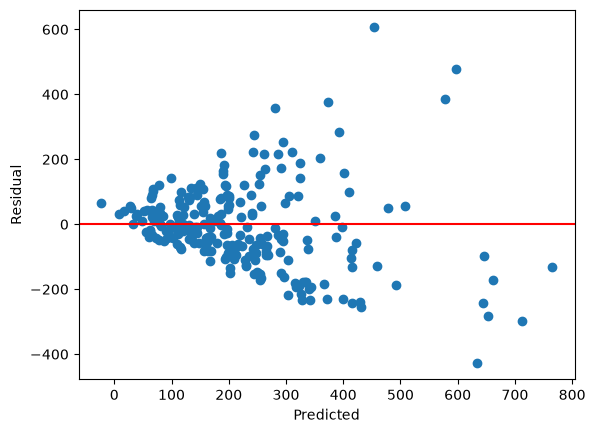

In [30]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel('Predicted'); plt.ylabel('Residual')
plt.show()

In [31]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error

# 20 features, only 5 truly informative
X, y = make_regression(n_samples=200, n_features=20, n_informative=5,
                       noise=10, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'OLS':        LinearRegression(),
    'Ridge (L2)': Ridge(alpha=1.0),
    'Lasso (L1)': Lasso(alpha=1.0),
    'ElasticNet': ElasticNet(alpha=1.0, l1_ratio=0.5),
}

for name, m in models.items():
    pipe = Pipeline([('sc', StandardScaler()), ('m', m)]).fit(X_train, y_train)
    rmse = np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
    coefs = pipe.named_steps['m'].coef_
    print(f"{name:12s} RMSE={rmse:6.2f}  zero weights={np.sum(coefs == 0)}")

OLS          RMSE=  8.37  zero weights=0
Ridge (L2)   RMSE=  8.36  zero weights=0
Lasso (L1)   RMSE=  8.02  zero weights=13
ElasticNet   RMSE= 48.84  zero weights=2


In [33]:
X = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])])

In [34]:
X

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19
0,0.020794,-0.728003,-1.009731,0.693106,0.200569,-0.827590,0.619154,0.061680,0.428817,-0.367028,0.086144,-2.921350,0.903935,-1.015822,0.176442,2.057495,-2.362932,-1.072139,1.148637,0.436560
1,-0.388177,0.170416,-0.337086,-1.975467,0.056650,-1.209695,-0.613403,0.486502,0.064474,-0.144088,0.599929,1.218762,1.490726,-0.070499,-0.939335,-0.302470,0.148667,1.530751,0.529693,-0.213443
2,1.024063,0.592527,2.006093,0.932591,0.722381,-1.525656,2.061504,-0.399636,0.224685,-1.760809,1.262584,2.558199,0.184551,1.726964,-1.418366,1.208366,1.542110,-0.551858,-0.372833,-0.564248
3,0.288694,0.260322,-0.670620,-1.027675,-0.128538,0.969457,1.392465,0.092845,0.159856,-0.866175,0.427194,1.775311,0.919154,-0.548725,1.265708,-0.250047,1.000582,-0.646227,-1.881849,-1.193637
4,-0.359630,0.301107,-0.848429,-0.351921,0.874517,-0.456121,0.573128,-1.042044,-0.487203,-1.296117,0.181427,-0.557423,-0.926698,-1.203201,-0.769996,-1.785866,-0.031439,0.595029,-0.649765,-0.412998
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.007063,-0.660321,0.575205,0.668742,0.439501,0.695538,0.500666,1.674492,-0.005596,-0.387100,0.849102,-0.071599,-0.357029,0.457773,-1.091701,0.049774,0.890383,-0.293967,0.778937,-1.517874
196,0.650450,-1.503080,0.522514,0.462061,-1.725807,-0.597510,0.418398,-0.981166,-0.464404,-0.251539,1.422370,0.978858,-0.808266,1.194109,0.783391,1.401599,-0.830444,1.738900,-0.677565,0.085318
197,-0.407036,0.686318,0.730764,1.321304,-0.358340,-1.866540,0.014273,-0.181224,-0.649373,-0.600424,1.007514,0.790626,0.892597,0.744192,1.419603,-0.953939,-1.211172,-0.684630,-0.647542,-1.970104
198,0.160490,2.212531,0.364140,-1.114046,-0.496932,0.782874,0.007178,-0.035008,-0.811001,0.212740,-0.431126,0.550798,-0.825654,-0.989958,0.258661,-2.086478,0.149363,0.408053,-0.182569,0.444774
